# Robust depth estimation from degraded RGB images: U-Net loss comparison

**Task.** Predict a depth map from a single RGB image that is both very dark (low light) and noisy. Data: DLP Week 11 Kaggle competition, 6,686 training pairs, 836 validation pairs, 836 test images, all 256×256.

**How the score works.** The course's `imgs2csv.py` resizes every depth map to 128×128 and min-max rescales it to 0–255 **per image** before RMSE is computed. So only the *relative* depth layout inside each image matters; absolute scale and offset don't. This notebook trains on per-image normalised depth and validates with exactly the same steps as the submission script.

**Comparison.** Same U-Net (ImageNet-pretrained ResNet-34 encoder), same data and schedule, two losses:
- **A:** L1 on normalised depth
- **B:** L1 + gradient loss (penalises differences in horizontal and vertical depth gradients, to keep object edges sharp)

The better model, with horizontal-flip test-time augmentation if it helps on validation, makes the submission.

Kaggle settings: GPU T4, Internet on.

In [1]:
!pip install -q segmentation-models-pytorch

In [2]:
import os, glob, time, random, hashlib, shutil
import numpy as np, pandas as pd, cv2, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from torch.utils.data import Dataset, DataLoader

ROOT = "/kaggle/input/competitions/depth-estimation/competition-data/competition-data"
OUT = "/kaggle/working"
FIG_DIR = f"{OUT}/images"
PRED_DIR = f"{OUT}/predictions"
os.makedirs(FIG_DIR, exist_ok=True)

SEED, EPOCHS, BATCH, LR, WORKERS = 42, 20, 16, 3e-4, 2
DEVICE = "cuda"

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)
torch.backends.cudnn.benchmark = True
print("torch", torch.__version__, "| smp", smp.__version__, "| GPU", torch.cuda.get_device_name(0))

torch 2.11.0+cu130 | smp 0.6.0 | GPU Tesla T4


## 1. Load the data into memory

The whole dataset is about 2 GB as uint8 arrays, so it is read once and kept in RAM; every epoch then avoids disk reads.

In [3]:
def read_split(split, with_depth):
    files = sorted(os.listdir(f"{ROOT}/{split}/images"))
    imgs = np.stack([cv2.cvtColor(cv2.imread(f"{ROOT}/{split}/images/{f}", cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
                     for f in files])
    deps = (np.stack([cv2.imread(f"{ROOT}/{split}/depths/{f}", cv2.IMREAD_UNCHANGED) for f in files])
            if with_depth else None)
    return files, imgs, deps

t0 = time.time()
train_files, train_imgs, train_deps = read_split("training", True)
val_files, val_imgs, val_deps = read_split("validation", True)
test_files, test_imgs, _ = read_split("testing", False)
print(f"loaded in {time.time() - t0:.0f} s")
print("train", train_imgs.shape, train_deps.shape, "| val", val_imgs.shape, val_deps.shape, "| test", test_imgs.shape)
print("RGB mean brightness (0-255): train %.1f, val %.1f, test %.1f"
      % (train_imgs.mean(), val_imgs.mean(), test_imgs.mean()))

loaded in 101 s
train (6686, 256, 256, 3) (6686, 256, 256) | val (836, 256, 256, 3) (836, 256, 256) | test (836, 256, 256, 3)
RGB mean brightness (0-255): train 9.4, val 9.4, test 9.4


## 2. Overlap between training and validation

Some scenes appear more than once with an identical depth map (the same scene with a different noise sample). Validation images whose depth map also appears in training are "seen" scenes and will score optimistically, so validation is reported on all 836 images and separately on the unseen ones.

In [4]:
h = lambda a: hashlib.md5(a.tobytes()).hexdigest()
train_hashes = {h(d) for d in train_deps}
val_seen = np.array([h(d) in train_hashes for d in val_deps])
unseen_idx = np.where(~val_seen)[0]
print(f"unique training depth maps: {len(train_hashes)} of {len(train_deps)}")
print(f"validation images whose depth map is also in training: {val_seen.sum()} of {len(val_deps)}; unseen: {len(unseen_idx)}")

unique training depth maps: 5868 of 6686
validation images whose depth map is also in training: 240 of 836; unseen: 596


## 3. Pre-processing, targets and the Kaggle metric

- **Input:** the images use only a small part of the 0–255 range (mean brightness about 10). Each image is divided by its own 99th-percentile value and clipped, which stretches contrast so the ImageNet-pretrained encoder sees a normal brightness range. Then ImageNet mean/std normalisation.
- **Target:** depth min-max normalised to [0, 1] per image, matching how the score treats depth. The model ends in a sigmoid.
- **Metric:** predictions are saved as uint8 PNGs, then `submission_pixels` applies the same steps as `imgs2csv.py` (resize to 128, per-image min-max, uint8) to predictions and ground truth. RMSE is taken over all pixels of all images; Kaggle's exact formula isn't published, so this is an assumption.

In [5]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

def preprocess(img_u8):
    x = img_u8.astype(np.float32)
    x = np.clip(x / max(np.percentile(x, 99), 1.0), 0, 1)   # per-image contrast stretch for low light
    return (x - MEAN) / STD

def normalise_depth(d):
    d = d.astype(np.float32)
    return (d - d.min()) / (d.max() - d.min() + 1e-6)

def submission_pixels(img_u8):
    # same steps as the course's imgs2csv.py
    image = cv2.resize(img_u8, (128, 128))
    image = image / 255.
    image = (image - np.min(image)) / (np.max(image) - np.min(image) + 1e-6)
    return np.uint8(image * 255.)

def pred_to_png(p):
    return np.uint8(np.round(np.clip(p, 0, 1) * 255))

VAL_GT = np.stack([submission_pixels(d) for d in val_deps]).astype(np.float64)

def kaggle_rmse(preds, idx=None):
    P = np.stack([submission_pixels(pred_to_png(p)) for p in preds]).astype(np.float64)
    G = VAL_GT
    if idx is not None:
        P, G = P[idx], G[idx]
    return float(np.sqrt(np.mean((P - G) ** 2)))

class DepthDataset(Dataset):
    def __init__(self, imgs, deps=None, augment=False):
        self.imgs, self.deps, self.augment = imgs, deps, augment
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        x = preprocess(self.imgs[i])
        y = normalise_depth(self.deps[i]) if self.deps is not None else np.zeros(x.shape[:2], np.float32)
        if self.augment and random.random() < 0.5:          # horizontal flip keeps depth valid
            x, y = x[:, ::-1], y[:, ::-1]
        x = torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))
        y = torch.from_numpy(np.ascontiguousarray(y))[None]
        return x, y

train_dl = DataLoader(DepthDataset(train_imgs, train_deps, augment=True), batch_size=BATCH, shuffle=True,
                      num_workers=WORKERS, pin_memory=True, drop_last=True,
                      generator=torch.Generator().manual_seed(SEED))
val_dl = DataLoader(DepthDataset(val_imgs, val_deps), batch_size=32, num_workers=WORKERS)
test_dl = DataLoader(DepthDataset(test_imgs), batch_size=32, num_workers=WORKERS)
print(len(train_dl), "training batches per epoch")

417 training batches per epoch


## 4. Model, losses and training loop

- U-Net with a ResNet-34 encoder pretrained on ImageNet (`segmentation_models_pytorch`).
- AdamW, one-cycle learning-rate schedule (10% warm-up), mixed precision, 20 epochs, batch 16.
- After every epoch the model is scored with the Kaggle metric on validation, and the best epoch is kept.

In [6]:
def make_model(pretrained=True):
    return smp.Unet(encoder_name="resnet34", encoder_weights="imagenet" if pretrained else None,
                    in_channels=3, classes=1)

def gradient_loss(p, t):
    dpx, dtx = p[..., :, 1:] - p[..., :, :-1], t[..., :, 1:] - t[..., :, :-1]
    dpy, dty = p[..., 1:, :] - p[..., :-1, :], t[..., 1:, :] - t[..., :-1, :]
    return (dpx - dtx).abs().mean() + (dpy - dty).abs().mean()

LOSSES = {
    "A_l1":      lambda p, t: F.l1_loss(p, t),
    "B_l1_grad": lambda p, t: F.l1_loss(p, t) + gradient_loss(p, t),
}

@torch.no_grad()
def predict(model, loader, tta=False):
    model.eval()
    out = []
    for x, _ in loader:
        x = x.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            p = torch.sigmoid(model(x))
            if tta:
                p = (p + torch.sigmoid(model(x.flip(-1))).flip(-1)) / 2
        out.append(p.float().squeeze(1).cpu().numpy())
    return np.concatenate(out)

def train_variant(name):
    seed_everything(SEED)
    loss_fn = LOSSES[name]
    model = make_model().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(train_dl), pct_start=0.1)
    scaler = torch.amp.GradScaler()
    history, best = [], float("inf")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        t0, loss_sum, l1_sum, n = time.time(), 0.0, 0.0, 0
        for x, y in train_dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16):
                p = torch.sigmoid(model(x))
            p = p.float()
            loss = loss_fn(p, y)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            loss_sum += loss.item() * len(x); l1_sum += F.l1_loss(p, y).item() * len(x); n += len(x)
        rmse = kaggle_rmse(predict(model, val_dl))
        history.append(dict(epoch=epoch, train_loss=loss_sum / n, train_l1=l1_sum / n, val_rmse=rmse,
                            seconds=time.time() - t0))
        flag = ""
        if rmse < best:
            best, flag = rmse, "  <- best"
            torch.save(model.state_dict(), f"{OUT}/{name}.pt")
        print(f"[{name}] epoch {epoch:2d} | train loss {loss_sum / n:.4f} | train L1 {l1_sum / n:.4f} "
              f"| val RMSE {rmse:.3f} | {time.time() - t0:.0f} s{flag}")
    return pd.DataFrame(history)

## 5. Train variant A (L1)

In [7]:
histories = {}
histories["A_l1"] = train_variant("A_l1")

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[A_l1] epoch  1 | train loss 0.1250 | train L1 0.1250 | val RMSE 30.893 | 56 s  <- best
[A_l1] epoch  2 | train loss 0.0652 | train L1 0.0652 | val RMSE 25.695 | 52 s  <- best
[A_l1] epoch  3 | train loss 0.0560 | train L1 0.0560 | val RMSE 22.998 | 55 s  <- best
[A_l1] epoch  4 | train loss 0.0504 | train L1 0.0504 | val RMSE 21.094 | 54 s  <- best
[A_l1] epoch  5 | train loss 0.0468 | train L1 0.0468 | val RMSE 20.915 | 55 s  <- best
[A_l1] epoch  6 | train loss 0.0434 | train L1 0.0434 | val RMSE 20.504 | 55 s  <- best
[A_l1] epoch  7 | train loss 0.0407 | train L1 0.0407 | val RMSE 19.568 | 55 s  <- best
[A_l1] epoch  8 | train loss 0.0381 | train L1 0.0381 | val RMSE 18.789 | 55 s  <- best
[A_l1] epoch  9 | train loss 0.0364 | train L1 0.0364 | val RMSE 18.343 | 55 s  <- best
[A_l1] epoch 10 | train loss 0.0339 | train L1 0.0339 | val RMSE 17.919 | 55 s  <- best
[A_l1] epoch 11 | train loss 0.0317 | train L1 0.0317 | val RMSE 17.373 | 55 s  <- best
[A_l1] epoch 12 | train loss 0.0

## 6. Train variant B (L1 + gradient loss)

In [8]:
histories["B_l1_grad"] = train_variant("B_l1_grad")

[B_l1_grad] epoch  1 | train loss 0.1684 | train L1 0.1293 | val RMSE 30.807 | 55 s  <- best
[B_l1_grad] epoch  2 | train loss 0.0760 | train L1 0.0661 | val RMSE 26.836 | 55 s  <- best
[B_l1_grad] epoch  3 | train loss 0.0658 | train L1 0.0570 | val RMSE 24.404 | 55 s  <- best
[B_l1_grad] epoch  4 | train loss 0.0597 | train L1 0.0513 | val RMSE 22.271 | 55 s  <- best
[B_l1_grad] epoch  5 | train loss 0.0561 | train L1 0.0479 | val RMSE 22.009 | 55 s  <- best
[B_l1_grad] epoch  6 | train loss 0.0526 | train L1 0.0444 | val RMSE 20.881 | 55 s  <- best
[B_l1_grad] epoch  7 | train loss 0.0501 | train L1 0.0421 | val RMSE 19.501 | 55 s  <- best
[B_l1_grad] epoch  8 | train loss 0.0477 | train L1 0.0397 | val RMSE 18.884 | 55 s  <- best
[B_l1_grad] epoch  9 | train loss 0.0450 | train L1 0.0371 | val RMSE 18.935 | 55 s
[B_l1_grad] epoch 10 | train loss 0.0431 | train L1 0.0351 | val RMSE 18.568 | 55 s  <- best
[B_l1_grad] epoch 11 | train loss 0.0408 | train L1 0.0329 | val RMSE 17.928 | 

## 7. Results on validation

Each variant's best checkpoint is scored with and without horizontal-flip test-time augmentation (TTA), on all 836 validation images and on the unseen ones only.

In [9]:
models, val_preds, rows = {}, {}, []
for name in LOSSES:
    m = make_model(pretrained=False).to(DEVICE)
    m.load_state_dict(torch.load(f"{OUT}/{name}.pt", map_location=DEVICE))
    models[name] = m
    h = histories[name]
    for tta in (False, True):
        p = predict(m, val_dl, tta=tta)
        val_preds[(name, tta)] = p
        rows.append(dict(variant=name, tta=tta, best_epoch=int(h.loc[h.val_rmse.idxmin(), "epoch"]),
                         rmse_all=kaggle_rmse(p), rmse_unseen=kaggle_rmse(p, unseen_idx)))
results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))
print("\nmean seconds per epoch:", {k: round(v.seconds.mean()) for k, v in histories.items()})

  variant   tta  best_epoch  rmse_all  rmse_unseen
     A_l1 False          19    15.526       16.911
     A_l1  True          19    15.350       16.715
B_l1_grad False          20    16.153       17.555
B_l1_grad  True          20    15.915       17.325

mean seconds per epoch: {'A_l1': 55, 'B_l1_grad': 55}


In [10]:
no_tta = results[~results.tta]
best_name = no_tta.loc[no_tta.rmse_all.idxmin(), "variant"]
r = results[results.variant == best_name].set_index("tta")
use_tta = bool(r.loc[True, "rmse_all"] < r.loc[False, "rmse_all"])
print(f"chosen: {best_name}, TTA: {use_tta}, validation RMSE {r.loc[use_tta, 'rmse_all']:.3f}")

# error by brightness: split validation into thirds by mean RGB brightness
bright = val_imgs.mean(axis=(1, 2, 3))
cuts = np.quantile(bright, [1 / 3, 2 / 3])
groups = {"darkest third": bright <= cuts[0],
          "middle third": (bright > cuts[0]) & (bright <= cuts[1]),
          "brightest third": bright > cuts[1]}
p = val_preds[(best_name, use_tta)]
for g, mask in groups.items():
    idx = np.where(mask)[0]
    print(f"{g:16s} brightness {bright[idx].min():5.1f}-{bright[idx].max():5.1f} | n={len(idx)} | RMSE {kaggle_rmse(p, idx):.3f}")

chosen: A_l1, TTA: True, validation RMSE 15.350
darkest third    brightness   3.4-  8.1 | n=279 | RMSE 19.176
middle third     brightness   8.1- 10.9 | n=278 | RMSE 15.576
brightest third  brightness  10.9- 21.9 | n=279 | RMSE 9.828


## 8. Figures

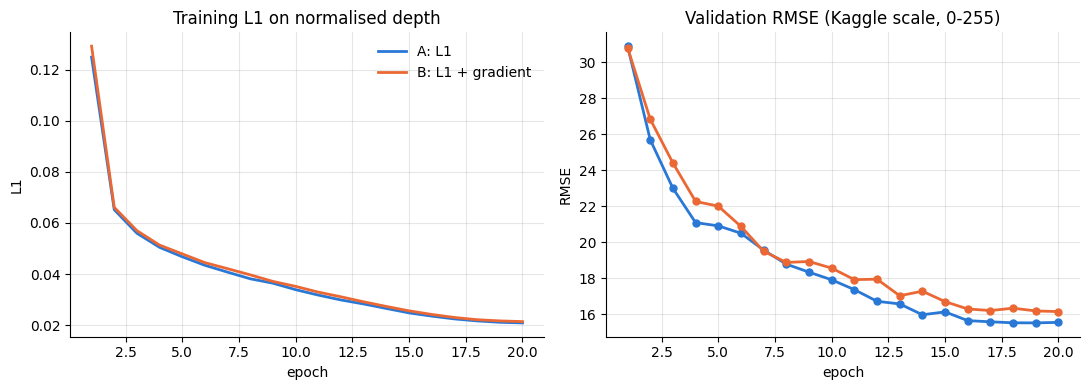

In [11]:
COLORS = {"A_l1": "#2a78d6", "B_l1_grad": "#eb6834"}
LABELS = {"A_l1": "A: L1", "B_l1_grad": "B: L1 + gradient"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, h in histories.items():
    axes[0].plot(h.epoch, h.train_l1, color=COLORS[name], lw=2, label=LABELS[name])
    axes[1].plot(h.epoch, h.val_rmse, color=COLORS[name], lw=2, marker="o", ms=5, label=LABELS[name])
axes[0].set(title="Training L1 on normalised depth", xlabel="epoch", ylabel="L1")
axes[1].set(title="Validation RMSE (Kaggle scale, 0-255)", xlabel="epoch", ylabel="RMSE")
for a in axes:
    a.grid(alpha=0.3); a.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/training_curves.png", dpi=150); plt.show()

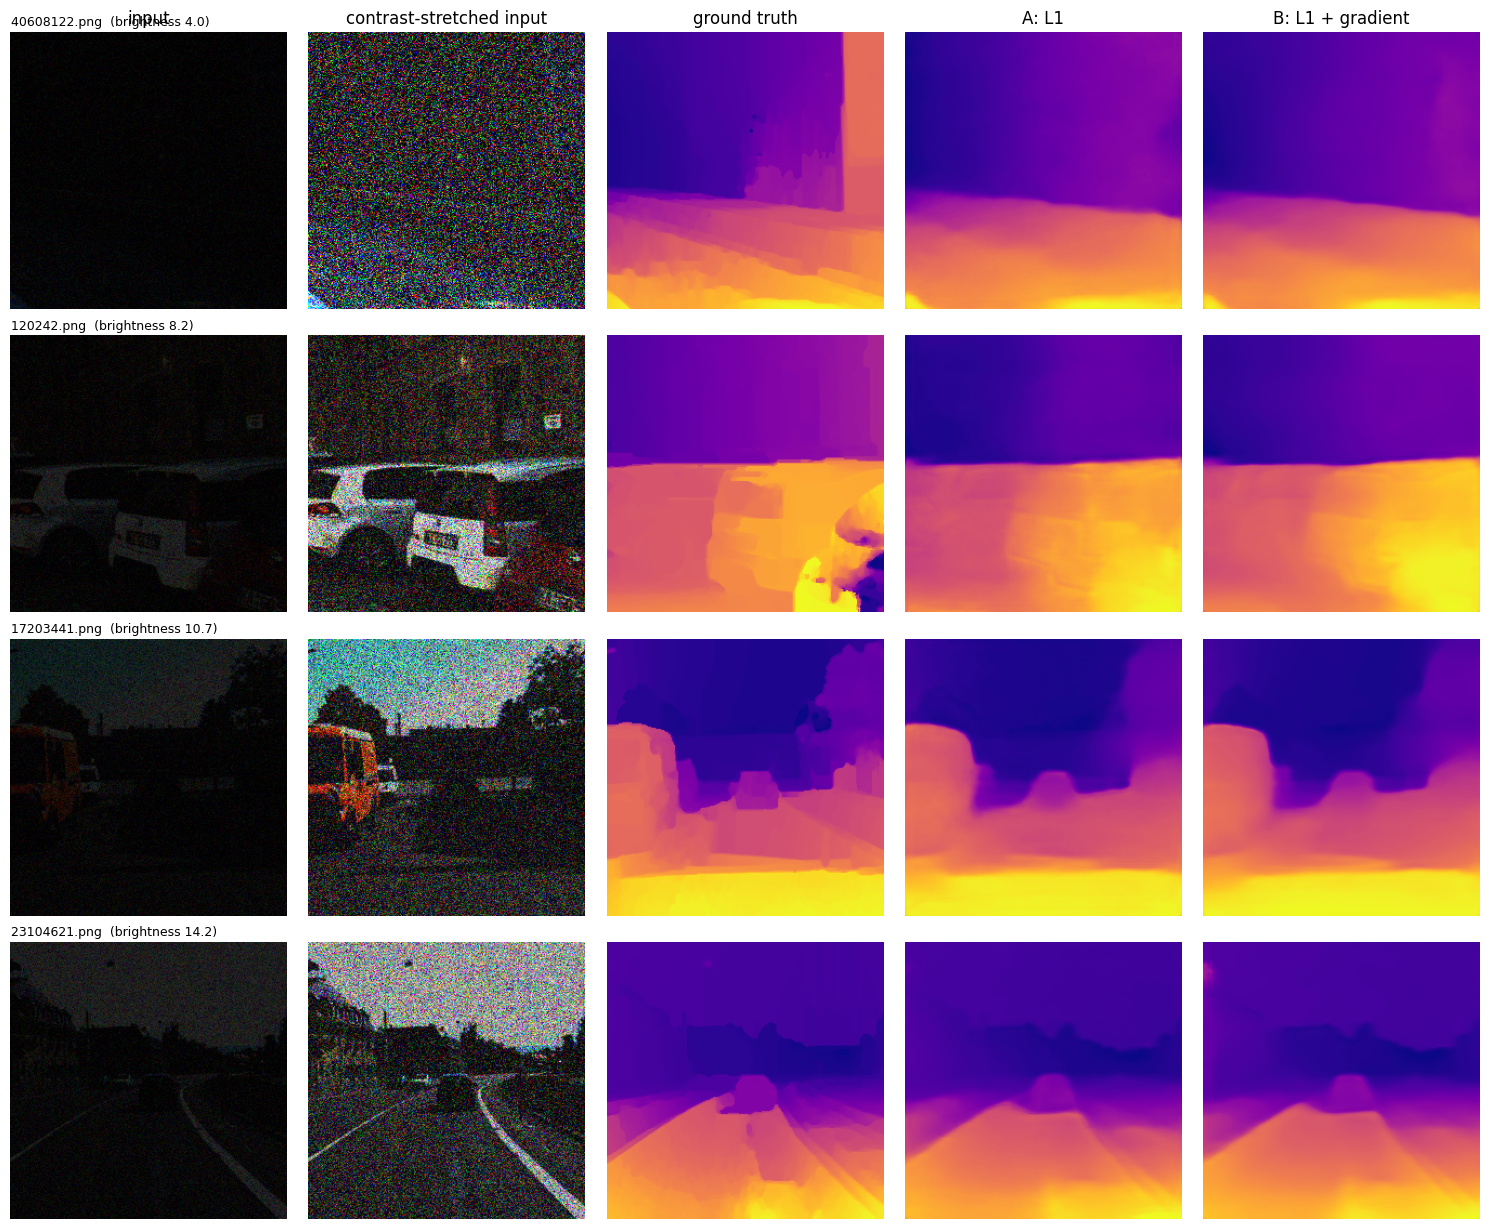

In [12]:
# four unseen validation images, from darkest to brightest
order = unseen_idx[np.argsort(bright[unseen_idx])]
picks = [order[int(q * (len(order) - 1))] for q in (0.05, 0.35, 0.65, 0.95)]
cols = ["input", "contrast-stretched input", "ground truth", "A: L1", "B: L1 + gradient"]
fig, ax = plt.subplots(len(picks), 5, figsize=(15, 3.1 * len(picks)))
for r, i in enumerate(picks):
    stretched = np.clip(val_imgs[i] / max(np.percentile(val_imgs[i], 99), 1.0), 0, 1)
    panels = [val_imgs[i], stretched, normalise_depth(val_deps[i]),
              normalise_depth(val_preds[("A_l1", False)][i]), normalise_depth(val_preds[("B_l1_grad", False)][i])]
    for c, im in enumerate(panels):
        ax[r, c].imshow(im, cmap=None if c < 2 else "plasma")
        ax[r, c].axis("off")
        if r == 0:
            ax[r, c].set_title(cols[c])
    ax[r, 0].text(0, -6, f"{val_files[i]}  (brightness {bright[i]:.1f})", fontsize=9)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/sample_predictions.png", dpi=120); plt.show()

## 9. Test predictions and submission

The chosen model predicts the 836 test images. Each prediction is saved as a single-channel uint8 PNG with the test image's filename, and the folder holds only these PNGs (the submission script numbers every file it finds). The CSV is then built with the course's `imgs2csv.py` function.

In [13]:
test_pred = predict(models[best_name], test_dl, tta=use_tta)
os.makedirs(PRED_DIR, exist_ok=True)
for f, p in zip(test_files, test_pred):
    cv2.imwrite(f"{PRED_DIR}/{f}", pred_to_png(p))
print(len(os.listdir(PRED_DIR)), "prediction PNGs written")

# provided by the course (imgs2csv.py), unchanged apart from being called with our paths
def images_to_csv_with_metadata(image_folder, output_csv):
    data = []
    for idx, filename in enumerate(sorted(os.listdir(image_folder))):
        if filename.endswith(".png"):
            filepath = os.path.join(image_folder, filename)
            image = cv2.imread(filepath, cv2.IMREAD_UNCHANGED)
            image = cv2.resize(image, (128, 128))
            image = image / 255.
            image = (image - np.min(image)) / (np.max(image) - np.min(image) + 1e-6)
            image = np.uint8(image * 255.)
            image_flat = image.flatten()
            row = [idx, filename] + image_flat.tolist()
            data.append(row)
    num_columns = len(data[0]) - 2 if data else 0
    column_names = ["id", "ImageID"] + [indx for indx in range(num_columns)]
    df = pd.DataFrame(data, columns=column_names)
    df.to_csv(output_csv, index=False)

images_to_csv_with_metadata(PRED_DIR, f"{OUT}/submission.csv")
sub = pd.read_csv(f"{OUT}/submission.csv")
sample = pd.read_csv("/kaggle/input/competitions/depth-estimation/predictions.csv", usecols=["id", "ImageID"])
print("submission shape:", sub.shape, "| sample shape:", (len(sample), sub.shape[1]))
print("same ImageIDs in the same order as the sample:", sub.ImageID.tolist() == sample.ImageID.tolist())

836 prediction PNGs written
submission shape: (836, 16386) | sample shape: (836, 16386)
same ImageIDs in the same order as the sample: True


In [14]:
# keep /kaggle/working tidy: submission.csv and images/ stay; checkpoints and PNG predictions go
for f in glob.glob(f"{OUT}/*.pt"):
    os.remove(f)
shutil.rmtree(PRED_DIR)
print(sorted(os.listdir(OUT)))

['__notebook__.ipynb', 'images', 'submission.csv']
